In [ ]:
 # Membaca dataset
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/diabetes_risk_dataset.csv')

DATA UNDERSTANDING

In [ ]:
# Menampilkan 10 baris pertama dari dataset
df.head(10)

,age,bmi,glucose_level,physical_activity_level,family_history,smoker,at_risk_diabetes
0,58,33.154816,71.049867,low,0,0,1
1,71,26.786882,125.964887,low,0,0,0
2,48,20.977319,61.876196,moderate,1,1,0
3,34,27.959924,137.648074,low,0,0,0
4,62,28.304175,65.879564,moderate,0,0,0
5,27,38.647437,155.877725,low,0,0,1
6,40,27.668951,94.438349,moderate,1,1,0
7,58,23.443522,96.010621,low,0,0,0
8,77,28.024477,87.334216,low,1,0,0
9,38,25.083408,60.000000,low,1,0,0


In [ ]:
# Menampilkan jumlah baris dan kolom dataset
(df.shape)

(100000, 7)

In [ ]:
# Menampilkan seluruh nama atribut yang terdapat dalam dataset
print(df.columns.tolist())

['age', 'bmi', 'glucose_level', 'physical_activity_level', 'family_history', 'smoker', 'at_risk_diabetes']


In [ ]:
# Menampilkan tipe data dari setiap atribut
print(df.dtypes)

age                          int64
bmi                        float64
glucose_level              float64
physical_activity_level     object
family_history               int64
smoker                       int64
at_risk_diabetes             int64
dtype: object


In [ ]:
# Menampilkan statistik deskriptif dari atribut numerik
df.describe()

,age,bmi,glucose_level,family_history,smoker,at_risk_diabetes
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,49.545230,27.034009,101.274228,0.299320,0.202000,0.207310
std,17.310892,4.957869,27.608618,0.457962,0.401494,0.405382
min,20.000000,15.000000,60.000000,0.000000,0.000000,0.000000
25%,35.000000,23.657095,79.809212,0.000000,0.000000,0.000000
50%,49.000000,27.002693,100.023378,0.000000,0.000000,0.000000
75%,65.000000,30.381817,120.199707,1.000000,0.000000,0.000000
max,79.000000,45.000000,200.000000,1.000000,1.000000,1.000000


In [ ]:
# Menampilkan jumlah data pada masing-masing kategori target
target = 'at_risk_diabetes'

print("Target:", target)
print(df[target].value_counts())

Target: at_risk_diabetes
at_risk_diabetes
0    79269
1    20731
Name: count, dtype: int64


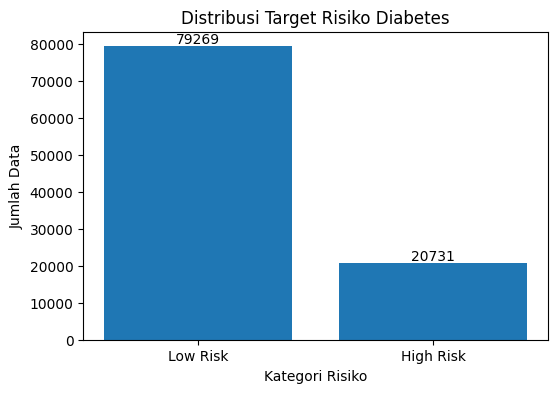

In [ ]:
# Membuat visualisasi distribusi kategori risiko diabetes
import matplotlib.pyplot as plt

distribusi_target = df[target].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ['Low Risk', 'High Risk'],
    distribusi_target.values
)

plt.title('Distribusi Target Risiko Diabetes')
plt.xlabel('Kategori Risiko')
plt.ylabel('Jumlah Data')

for i, nilai in enumerate(distribusi_target.values):
    plt.text(
        i,
        nilai,
        str(nilai),
        ha='center',
        va='bottom'
    )

plt.show()

In [ ]:
# Mengecek missing value
print(df.isnull().sum())

age                        0
bmi                        0
glucose_level              0
physical_activity_level    0
family_history             0
smoker                     0
at_risk_diabetes           0
dtype: int64


In [ ]:
# Mengecek duplikat
print("Jumlah duplikat:", df.duplicated().sum())

Jumlah duplikat: 6


In [ ]:
# Menampilkan baris data yang terdeteksi sebagai duplikat
df[df.duplicated()]

,age,bmi,glucose_level,physical_activity_level,family_history,smoker,at_risk_diabetes
52988,79,15.0,60.0,low,0,0,0
55907,62,15.0,60.0,low,0,0,0
70960,55,15.0,60.0,moderate,1,1,0
76367,76,15.0,60.0,moderate,0,0,0
76431,65,15.0,60.0,moderate,1,0,0
79949,30,15.0,60.0,low,0,0,0


In [ ]:
# Menghitung dan menampilkan korelasi atribut numerik terhadap target
corr = df.corr(numeric_only=True)

print(corr['at_risk_diabetes'].sort_values(ascending=False))

at_risk_diabetes    1.000000
bmi                 0.396735
age                 0.242708
glucose_level       0.203807
family_history      0.129374
smoker              0.115592
Name: at_risk_diabetes, dtype: float64


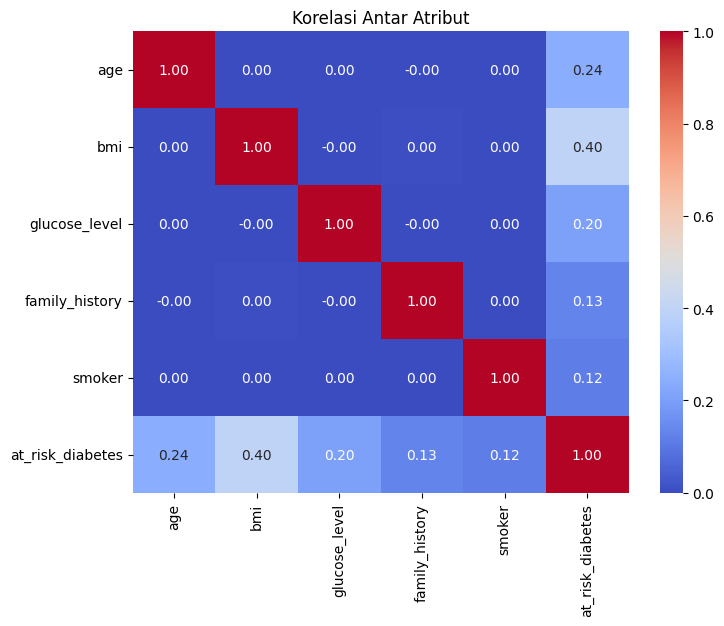

In [ ]:
# Membuat heatmap untuk melihat hubungan korelasi antar atribut
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Korelasi Antar Atribut')
plt.show()

PREPROCESSING

In [ ]:
# Menangani data duplikat
df = df.drop_duplicates().reset_index(drop=True)
print("Jumlah duplikat setelah ditangani:", df.duplicated().sum())

Jumlah duplikat setelah ditangani: 0


In [ ]:
print(df.shape)

(99994, 7)


In [ ]:
# Mengecek outlier pada atribut numerik menggunakan metode IQR
kolom_numerik = [
    'age',
    'bmi',
    'glucose_level'
]

for col in kolom_numerik:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    outlier = df[
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ]

    print("\n", col)
    print("Batas bawah:", batas_bawah)
    print("Batas atas:", batas_atas)
    print("Jumlah outlier:", len(outlier))


 age
Batas bawah: -10.0
Batas atas: 110.0
Jumlah outlier: 0

 bmi
Batas bawah: 13.570091895693112
Batas atas: 40.469529174659115
Jumlah outlier: 343

 glucose_level
Batas bawah: 19.234648113370845
Batas atas: 180.77979599413686
Jumlah outlier: 381


In [ ]:
# Mengubah atribut aktivitas fisik menjadi beberapa kolom biner menggunakan One-Hot Encoding
df_encoded = pd.get_dummies(
    df,
    columns=['physical_activity_level'],
    dtype=int
)

display(df_encoded.head())

,age,bmi,glucose_level,family_history,smoker,at_risk_diabetes,physical_activity_level_high,physical_activity_level_low,physical_activity_level_moderate
0,58,33.154816,71.049867,0,0,1,0,1,0
1,71,26.786882,125.964887,0,0,0,0,1,0
2,48,20.977319,61.876196,1,1,0,0,0,1
3,34,27.959924,137.648074,0,0,0,0,1,0
4,62,28.304175,65.879564,0,0,0,0,0,1


In [ ]:
# Menentukan fitur yang digunakan
fitur_terpilih = [
    kolom for kolom in df_encoded.columns
    if kolom != target
]

print("\nFitur yang digunakan:")
print(fitur_terpilih)


Fitur yang digunakan:
['age', 'bmi', 'glucose_level', 'family_history', 'smoker', 'physical_activity_level_high', 'physical_activity_level_low', 'physical_activity_level_moderate']


TRAINING

In [ ]:
# Menentukan fitur X dan target y untuk proses training
X = df_encoded[fitur_terpilih].copy()
y = df_encoded[target].copy()

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

Ukuran X: (99994, 8)
Ukuran y: (99994,)


In [ ]:
# Membandingkan tiga cara pembagian data menggunakan Decision Tree sebagai model uji
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

skenario = {
    '80:20': 0.20,
    '70:30': 0.30,
    '60:40': 0.40
}

hasil_split = []

for nama_split, test_size in skenario.items():

    X_train_uji, X_test_uji, y_train_uji, y_test_uji = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    model_uji = DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        random_state=42
    )

    model_uji.fit(
        X_train_uji,
        y_train_uji
    )

    y_pred_uji = model_uji.predict(
        X_test_uji
    )

    accuracy = accuracy_score(
        y_test_uji,
        y_pred_uji
    )

    hasil_split.append({
        'Pembagian Data': nama_split,
        'Accuracy': accuracy
    })

hasil_split = pd.DataFrame(hasil_split)
display(hasil_split)

,Pembagian Data,Accuracy
0,80:20,0.920946
1,70:30,0.919697
2,60:40,0.919446


In [ ]:
# Menentukan pembagian data dengan Accuracy tertinggi untuk digunakan pada training
index_split_terbaik = hasil_split['Accuracy'].idxmax()

split_terpilih = hasil_split.loc[
    index_split_terbaik,
    'Pembagian Data'
]

accuracy_split_terpilih = hasil_split.loc[
    index_split_terbaik,
    'Accuracy'
]

print("Pembagian data terpilih:", split_terpilih)
print("Accuracy tertinggi:", accuracy_split_terpilih)

Pembagian data terpilih: 80:20
Accuracy tertinggi: 0.9209460473023651


In [ ]:
# Membagi dataset menggunakan skenario pembagian data yang telah terpilih
test_size_terpilih = skenario[split_terpilih]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=test_size_terpilih,
    random_state=42,
    stratify=y
)

print("Ukuran data training:", X_train.shape)
print("Ukuran data testing:", X_test.shape)

Ukuran data training: (79995, 8)
Ukuran data testing: (19999, 8)


In [ ]:
# Melakukan Standard Scaling pada atribut numerik
from sklearn.preprocessing import StandardScaler

kolom_scaling = [
    'age',
    'bmi',
    'glucose_level'
]

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[kolom_scaling] = scaler.fit_transform(
    X_train[kolom_scaling]
)

X_test[kolom_scaling] = scaler.transform(
    X_test[kolom_scaling]
)

In [ ]:
# Melatih model XGBoost menggunakan data training
!pip install -q xgboost

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(
    X_train,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
# Melatih model Random Forest menggunakan data training
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

RandomForestClassifier(random_state=42)

In [ ]:
# Melatih model Decision Tree menggunakan data training
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    random_state=42
)

dt_model.fit(
    X_train,
    y_train
)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [ ]:
# Membandingkan kinerja XGBoost, Random Forest, dan Decision Tree menggunakan beberapa metrik
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_pred_xgb = xgb_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)
y_pred_dt = dt_model.predict(X_test)

models = {
    'XGBoost': y_pred_xgb,
    'Random Forest': y_pred_rf,
    'Decision Tree': y_pred_dt
}

hasil_model = []

for nama, prediksi in models.items():

    hasil_model.append({
        'Model': nama,
        'Accuracy': accuracy_score(y_test, prediksi),
        'Precision': precision_score(y_test, prediksi),
        'Recall': recall_score(y_test, prediksi),
        'F1-Score': f1_score(y_test, prediksi)
    })

hasil_model = pd.DataFrame(hasil_model)

display(hasil_model)

,Model,Accuracy,Precision,Recall,F1-Score
0,XGBoost,0.920546,0.845447,0.754703,0.797502
1,Random Forest,0.912146,0.812614,0.748915,0.779465
2,Decision Tree,0.920946,0.840637,0.763386,0.800152


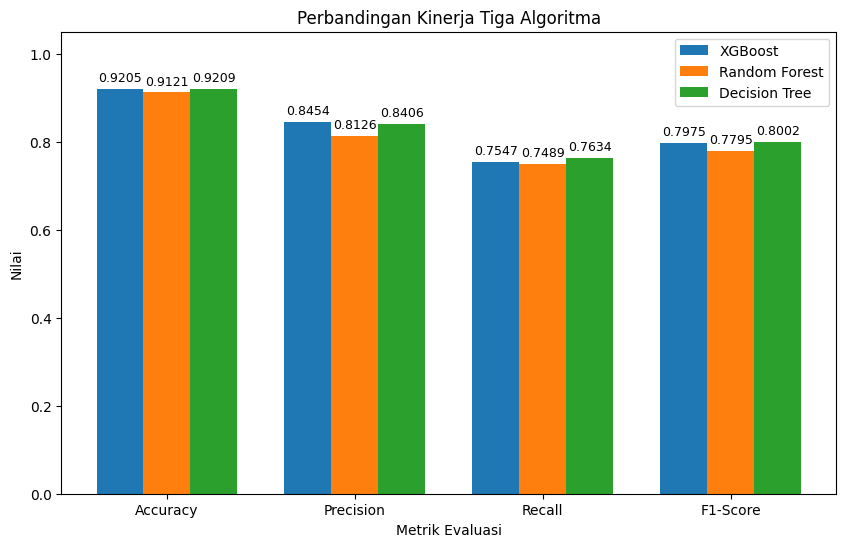

In [ ]:
# Membuat visualisasi perbandingan kinerja ketiga algoritma
import numpy as np
import matplotlib.pyplot as plt

metrik = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score'
]

x = np.arange(len(metrik))
width = 0.25

plt.figure(figsize=(10, 6))

for i, model in enumerate([
    'XGBoost',
    'Random Forest',
    'Decision Tree'
]):

    nilai = hasil_model[
        hasil_model['Model'] == model
    ][metrik].values[0]

    bars = plt.bar(
        x + (i - 1) * width,
        nilai,
        width,
        label=model
    )

    for bar, angka in zip(bars, nilai):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f'{angka:.4f}',
            ha='center',
            va='bottom',
            fontsize=9
        )

plt.xticks(x, metrik)
plt.xlabel('Metrik Evaluasi')
plt.ylabel('Nilai')
plt.title('Perbandingan Kinerja Tiga Algoritma')
plt.legend()
plt.ylim(0, 1.05)

plt.show()

In [ ]:
# Menentukan algoritma dengan nilai Accuracy tertinggi
index_model_terbaik = hasil_model['Accuracy'].idxmax()

model_terpilih = hasil_model.loc[
    index_model_terbaik,
    'Model'
]

accuracy_model_terpilih = hasil_model.loc[
    index_model_terbaik,
    'Accuracy'
]

print("Algoritma terpilih:", model_terpilih)
print("Accuracy tertinggi:", accuracy_model_terpilih)

Algoritma terpilih: Decision Tree
Accuracy tertinggi: 0.9209460473023651


EVALUATION

In [ ]:
# Mengevaluasi model Decision Tree pada data testing
y_pred_terpilih = dt_model.predict(X_test)

accuracy = accuracy_score(
    y_test,
    y_pred_terpilih
)

precision = precision_score(
    y_test,
    y_pred_terpilih
)

recall = recall_score(
    y_test,
    y_pred_terpilih
)

f1 = f1_score(
    y_test,
    y_pred_terpilih
)

print("Evaluasi Akhir Model")
print("--------------------")
print("Algoritma :", model_terpilih)
print("Accuracy  :", accuracy)
print("Precision :", precision)
print("Recall    :", recall)
print("F1-Score  :", f1)

Evaluasi Akhir Model
--------------------
Algoritma : Decision Tree
Accuracy  : 0.9209460473023651
Precision : 0.8406374501992032
Recall    : 0.7633863965267728
F1-Score  : 0.8001516875237011


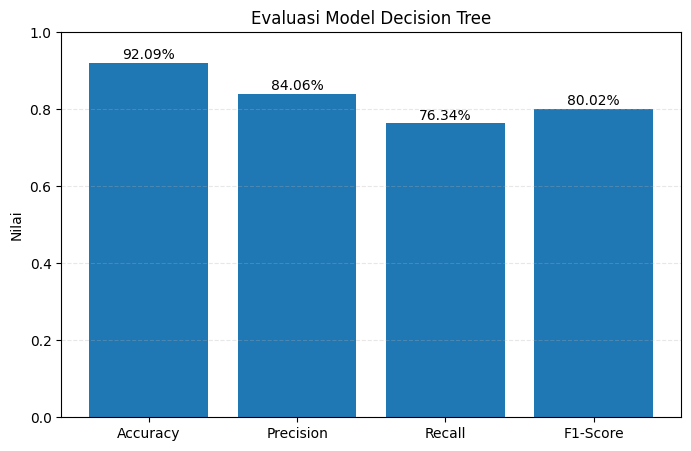

In [ ]:
# Visualisasi hasil evaluasi model
import matplotlib.pyplot as plt

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
values = [accuracy, precision, recall, f1]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, values)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.01,
        f'{value:.2%}',
        ha='center'
    )

plt.title('Evaluasi Model Decision Tree')
plt.ylabel('Nilai')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

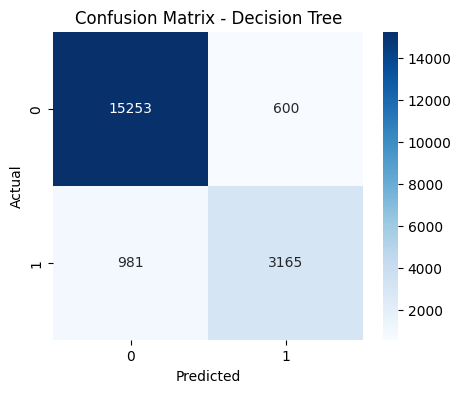

In [ ]:
# Menampilkan confusion matrix dari model terpilih
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred_terpilih
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title(f'Confusion Matrix - {model_terpilih}')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

PREDIKSI DATA BARU

In [ ]:
# Membuat satu data baru untuk melakukan prediksi risiko diabetes
data_baru = pd.DataFrame({
    'bmi': [28],
    'age': [50],
    'glucose_level': [120],
    'family_history': [1],
    'smoker': [0],
    'physical_activity_level_low': [0],
    'physical_activity_level_moderate': [0],
    'physical_activity_level_high': [1]
})

data_baru = data_baru[fitur_terpilih]

display(data_baru)

data_baru[kolom_scaling] = scaler.transform(
    data_baru[kolom_scaling]
)

prediksi = dt_model.predict(data_baru)

label_risiko = {
    0: 'Low Risk',
    1: 'High Risk'
}

hasil_prediksi = label_risiko[prediksi[0]]

print("Hasil Prediksi:", hasil_prediksi)

,age,bmi,glucose_level,family_history,smoker,physical_activity_level_high,physical_activity_level_low,physical_activity_level_moderate
0,50,28,120,1,0,1,0,0


Hasil Prediksi: Low Risk
